# Which stars belong together?
*Galactic archaeology with Gaia and Rubin*  
**Ani Chiti · Ioana Ciucă · Stanford PHYSICS 367**

On Monday, Ani picked out stars in Reticulum II by their colour and brightness, then checked where they fell on the sky. Today we’ll start with motion. If we pick stars that move together, do they also cluster on the sky? How do you expect they show up on a colour–magnitude diagram? Why?

We’ll try this with two clusters, the Pleiades and M5, then look for a steller stream known as GD-1. Allow **45 minutes for the Gaia exercises** and **10 more for an optional look at Rubin images**.

We are also excited to hear your plans for the [Gaia DR4 Sprint at KIPAC, December 2–4](https://kipac.stanford.edu/events/kipac-workshops/kipac-gaia-dr4-x-agentic-ai-sprint-decoding-milky-way-stanford), and hope this tutorial will be useful!

## Warm Up Chat with Neighbors ~ 5 min

Q: Two stars look close together on the sky. What would you measure to find out whether they might belong to the same star cluster? Please discuss with your neighbour.

| Gaia column | What it measures |
|---|---|
| `ra`, `dec` | Right ascension and declination in degrees. |
| `phot_g_mean_mag` | Apparent brightness in Gaia’s G band. Smaller magnitudes are brighter. |
| `bp_rp` | Colour (BP − RP). Larger values are redder. |
| `pmra`, `pmdec` | Proper motion in right ascension and declination, in milliarcseconds per year (mas/yr). Gaia includes the cos(dec) factor in `pmra`. |
| `parallax` | The apparent shift in position as Earth orbits the Sun, in milliarcseconds (mas). Nearer stars have larger parallaxes. |

Run the notebook from the top with the accompanying `gaia_data/` folder beside it. The three Gaia exercises download and save the data, which you then load or re-load. Try to work through the exercises with your neighbour, then you can open the worked answers to check your results.

<details>
<summary>Compare ideas [check me after discussion!] </summary>

A parallax comparison can reveal two stars at very different distances along the same line of sight. If their distances agree within the uncertainties, I’d next compare their proper motions.

</details>

In [35]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': False,
    'figure.constrained_layout.use': True,
})
TEAL, ORANGE, GREY = '#007C83', '#C76D33', '#B7BEC5'

data_dir = Path('gaia_data')
data_dir.mkdir(exist_ok=True)

In [36]:
def gaia_sample(query, name):
    """Read the class sample or fetch it from ESA if the query has changed."""
    table_path = data_dir / f'{name}.ecsv'
    query_path = data_dir / f'{name}.adql'
    if table_path.exists() and query_path.exists() and query_path.read_text().strip() == query.strip():
        return Table.read(table_path)

    from astroquery.gaia import Gaia
    table = Gaia.launch_job_async(query).get_results()
    table.write(table_path, overwrite=True)
    query_path.write_text(query.strip())
    return table

## 1. The Pleiades ~ 10 min

Start with stars within 1° of Alcyone in the Pleiades. Find the radius in the query below. What does `parallax_over_error > 10` require of each parallax measurement?

This notebook uses bits of the [ESA’s Pleiades tutorial](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_use_case_pleiades.ipynb)  -- which we encourage you to look at!

In [39]:
query = """
SELECT source_id, ra, dec, pmra, pmdec, phot_g_mean_mag, bp_rp
FROM gaiadr3.gaia_source
WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 56.87125, 24.10493, 1.0))
  AND ruwe < 1.4
  AND parallax_over_error > 10
  AND phot_g_mean_mag < 20.0
  AND bp_rp IS NOT NULL
  AND pmra IS NOT NULL
  AND pmdec IS NOT NULL
"""
pleiades = gaia_sample(query, 'pleiades_dr3')
display(pleiades[:5])

source_id,ra,dec,pmra,pmdec,phot_g_mean_mag,bp_rp
,deg,deg,mas / yr,mas / yr,mag,mag
int64,float64,float64,float64,float64,float32,float32
64908333213483776,56.942582482469064,23.108575618434905,2.510821794162581,1.3793951913874327,15.257369,1.194396
64909054767982848,57.03752869159789,23.13226879245885,3.9211423926684565,-0.7774875927702146,13.744706,0.98705864
64923344122211712,57.25750363405319,23.258994048675735,-3.6675913921020102,-0.43078846325340864,18.101778,2.4299202
64929773690286336,57.32943356298656,23.316206775862522,1.9253972004490896,-11.229172311938301,14.545646,0.77218723
64931216799282048,57.520305095232814,23.394173680608375,3.512472586710829,-2.3222679886069626,14.949414,0.8905411


### Select stars by proper motion

The circle is centred on the Pleiades’ proper motion, (+20, −45) mas/yr. On the right, the same stars appear in teal on a colour–magnitude diagram (CMD). Brighter stars are at the top.

Run the cell with a radius of 3 mas/yr. Before widening it to 6, try to predict where the extra stars will land on the CMD. Can you spot a star that makes you doubt its membership?

431 Pleiades candidates


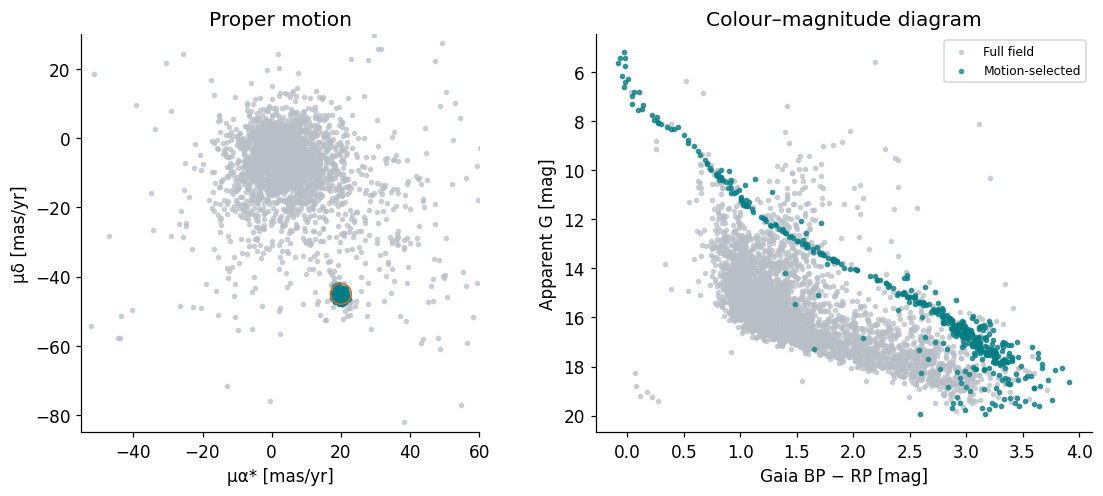

In [40]:
radius_pm = 3.0  # mas/yr
offset = np.hypot(pleiades['pmra'] - 20, pleiades['pmdec'] + 45)
selected = pleiades[offset < radius_pm]
print(f'{len(selected):,} Pleiades candidates')

fig, (ax_pm, ax_cmd) = plt.subplots(1, 2, figsize=(10, 4.4))
for table, colour, label in [(pleiades, GREY, 'Full field'),
                             (selected, TEAL, 'Motion-selected')]:
    ax_pm.scatter(table['pmra'], table['pmdec'], s=7, color=colour, alpha=.65)
    ax_cmd.scatter(table['bp_rp'], table['phot_g_mean_mag'], s=7,
                   color=colour, alpha=.65, label=label)
ax_pm.add_patch(plt.Circle((20, -45), radius_pm, fill=False, color=ORANGE))
ax_pm.set(xlim=(-55, 60), ylim=(-85, 30), aspect='equal',
          xlabel='μα* [mas/yr]', ylabel='μδ [mas/yr]', title='Proper motion')
ax_cmd.invert_yaxis()
ax_cmd.set(xlabel='Gaia BP − RP [mag]', ylabel='Apparent G [mag]', title='Colour–magnitude diagram')
ax_cmd.legend(fontsize=8)
plt.show()

<details>
<summary>Check your reading of the Pleiades</summary>

The last number in `CIRCLE` gives the 1° radius. The parallax cut requires a positive parallax with a fractional uncertainty below 10%. Widening the motion circle adds 25 stars to the first 431. Some join the faint red sequence. I’d check the funky star’s distance before including it.

</details>

## 2. Find M5 ~ 15 min

M5 is much farther away than the Pleiades. What would happen to its stars if you kept the same parallax cut?

This sample covers 0.6° around M5. The query keeps a random subset of stars with well-measured colours. Run it, then look for a clump of stars moving together.

In [41]:
query = """
SELECT source_id, ra, dec, pmra, pmdec, phot_g_mean_mag, bp_rp
FROM gaiadr3.gaia_source
WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 229.6384, 2.081, 0.6))
  AND ruwe < 1.4
  AND phot_bp_mean_flux_over_error > 10
  AND phot_rp_mean_flux_over_error > 10
  AND random_index < 300000000
  AND phot_g_mean_mag < 20.0
  AND bp_rp IS NOT NULL
  AND pmra IS NOT NULL
  AND pmdec IS NOT NULL
"""
stars = gaia_sample(query, 'm5_dr3')
display(stars[:5])

source_id,ra,dec,pmra,pmdec,phot_g_mean_mag,bp_rp
,deg,deg,mas / yr,mas / yr,mag,mag
int64,float64,float64,float64,float64,float32,float32
4420692915879176832,229.69744634665048,1.4944081601737407,9.62184395720977,-7.463996725303254,13.7577,0.8490448
4420696313197675648,229.74298147908758,1.6080927547423662,7.579917062339399,-5.6033846420046,18.462652,2.2068443
4420699611732574080,230.0486365469892,1.6480720281995866,-3.467022943040193,-1.0318647259144755,17.55333,0.8692379
4420794753847700480,230.05508594383974,1.735633688269955,4.326257941433499,-9.872275181550517,17.728088,0.8347111
4420795200524400256,230.0720066397885,1.7559505766479593,-3.158015201854866,-2.422252130256569,19.28701,0.9158611


### Estimate M5’s proper motion

Each hexagon counts stars with similar motions. Read the centre of the densest clump off the axes. Compare both numbers, including their signs, with your neighbour.

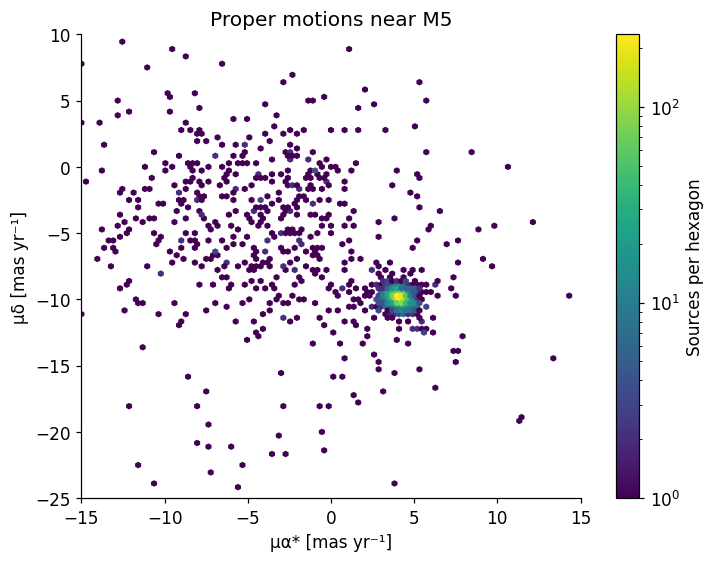

In [42]:
fig, ax = plt.subplots(figsize=(6.4, 5))
h = ax.hexbin(stars['pmra'], stars['pmdec'], gridsize=110, mincnt=1,
              bins='log', extent=(-15, 15, -25, 10), cmap='viridis')
fig.colorbar(h, ax=ax, label='Sources per hexagon')
ax.set(xlim=(-15, 15), ylim=(-25, 10), xlabel='μα* [mas yr⁻¹]',
       ylabel='μδ [mas yr⁻¹]', title='Proper motions near M5')
plt.show()

Use your estimate to select stars within 0.75 mas/yr of the centre. The Pleiades example shows how to measure the distance in the proper-motion plot with `np.hypot`. Try it below, or go straight to the worked selection.

In [7]:
# Put your code here. Use your centre and radius to select rows from stars.

In [43]:
# Worked selection. Change the centre to test your own estimate.
pmra_c, pmdec_c = 4.0, -10.0
radius_pm = 0.75  # Try 2.0 next.
delta_pm = np.hypot(stars['pmra'] - pmra_c, stars['pmdec'] - pmdec_c)
candidates = stars[delta_pm < radius_pm]
print(f'{len(candidates):,} / {len(stars):,} stars selected as M5 candidates')

1,710 / 2,798 stars selected as M5 candidates


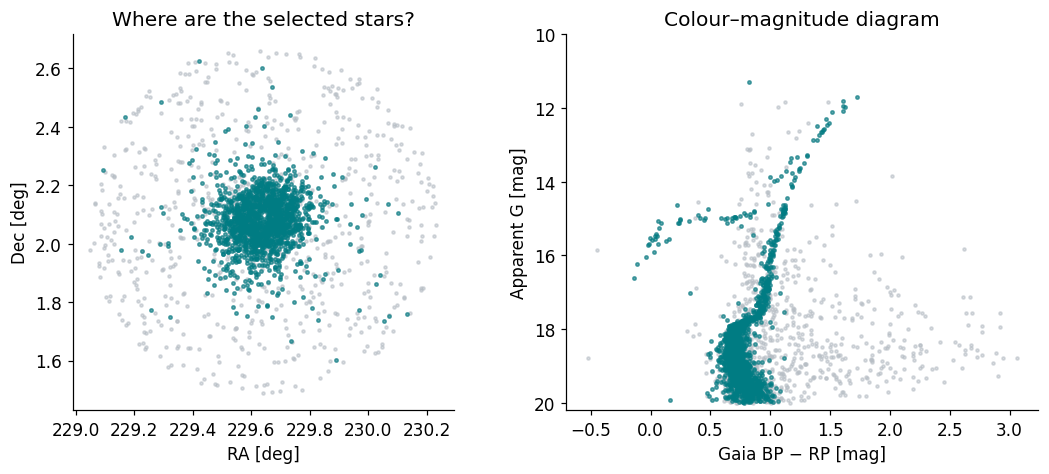

In [44]:
fig, (sky, cmd) = plt.subplots(1, 2, figsize=(9.5, 4.2))
for table, colour, size in [(stars, GREY, 4), (candidates, TEAL, 5)]:
    sky.scatter(table['ra'], table['dec'], s=size, color=colour, alpha=.55)
    cmd.scatter(table['bp_rp'], table['phot_g_mean_mag'], s=size, color=colour, alpha=.55)
sky.set(xlabel='RA [deg]', ylabel='Dec [deg]', aspect='equal', title='Where are the selected stars?')
cmd.set(xlabel='Gaia BP − RP [mag]', ylabel='Apparent G [mag]', ylim=(20.2, 10),
        title='Colour–magnitude diagram')
plt.show()

The teal stars passed a cut on motion alone. What else do they have in common? Widen the radius to 2 mas/yr and rerun the selection and plots. Which radius would you keep, and why?

<details>
<summary>Compare interpretations</summary>

The motion clump is near (+4, −10) mas/yr. With the narrow radius, 1,710 stars pass. They gather around the centre of M5 and trace a sequence in the CMD. The wider cut keeps 2,120. I’d try it to recover more faint members, then check how many extra stars follow the sequence. A precise-parallax cut would lose many distant M5 stars whose parallaxes are small compared with their errors.

</details>

## 3. Find the GD-1 stream ~ 15 min

M5's stars formed a compact group on the sky. What shape might you see if stars that once belonged to a cluster escaped and drifted along its orbit?

This Gaia DR3 field covers a circle of radius 6.5°. The query already sets broad limits on parallax, colour and motion. Both maps below use this same patch of sky.

In [45]:
gd1_query = """
SELECT source_id, ra, dec, pmra, pmdec
FROM gaiadr3.gaia_source
  WHERE 1 = CONTAINS(POINT('ICRS', ra, dec),
                   CIRCLE('ICRS', 142.22178, 27.92682, 6.5))
  AND parallax < 1 AND bp_rp BETWEEN -0.75 AND 2
  AND pmra BETWEEN -9 AND 2 AND pmdec BETWEEN -17 AND -5
"""
gd1 = gaia_sample(gd1_query, "gd1_dr3")

In this part of GD-1, stars move at about (−5, −13) mas/yr. Use the same distance in proper-motion space that you used for M5. Try selecting stars within **1 mas/yr** of this motion, then run the solution to see where they fall on the sky.

In [11]:
# Put your code here. Which rows of gd1 pass the motion cut?

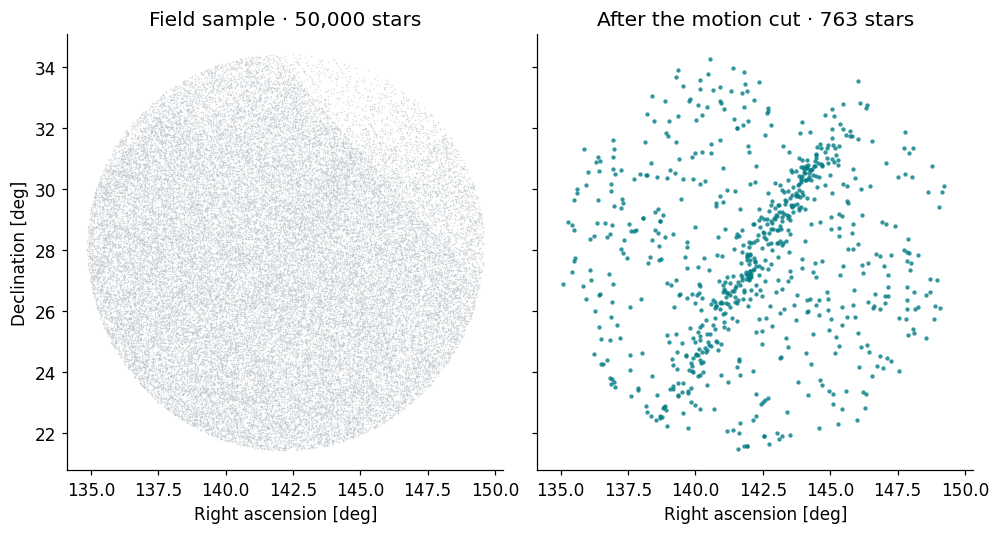

In [47]:
# Solution
pmra_c, pmdec_c = -5.0, -13.0  # mas/yr
distance_pm = np.hypot(gd1['pmra'] - pmra_c, gd1['pmdec'] - pmdec_c)
stream_candidates = gd1[distance_pm < 1.0]

fig, (before, after) = plt.subplots(1, 2, figsize=(9, 4.6), sharex=True, sharey=True)
before.scatter(gd1['ra'], gd1['dec'], s=1, color=GREY, alpha=.45, linewidths=0)
after.scatter(stream_candidates['ra'], stream_candidates['dec'],
              s=8, color=TEAL, alpha=.8, linewidths=0)
before.set_title(f'Field sample · {len(gd1):,} stars')
after.set_title(f'After the motion cut · {len(stream_candidates):,} stars')
before.set_ylabel('Declination [deg]')
for ax in (before, after):
    ax.set_xlabel('Right ascension [deg]')
    ax.set_aspect(1 / np.cos(np.deg2rad(27.93)))
plt.show()

Compare the two maps. What shape appears when you select stars by motion alone? How could stars that once shared a cluster have ended up spread across the sky like this?

Change `pmdec_c` from −13 to −10 mas/yr and rerun the map. What happens to the feature? Explain what this comparison tells you about the stars along it.

<details><summary>One interpretation</summary>

A band runs from lower left to upper right. Moving the selection away from GD-1's motion makes the band much harder to trace. A shared motion and an extended trail on the sky are both consistent with stars that escaped from a common parent. A field star can still pass the cut by chance.

</details>

We can also rotate the sky coordinates so that the longitude, ϕ₁, runs along GD-1 and latitude, ϕ₂, measures angular offset across it. In this view, stars tracing the stream should form a narrow band. Please have a look at Koposov, Rix & Hogg (2024), Appendix (https://arxiv.org/pdf/0907.1085#page=15).

For more fun reading about GD-1, you can have a look here: https://astrobites.org/2018/06/21/clearing-up-stellar-streams-with-gaia/


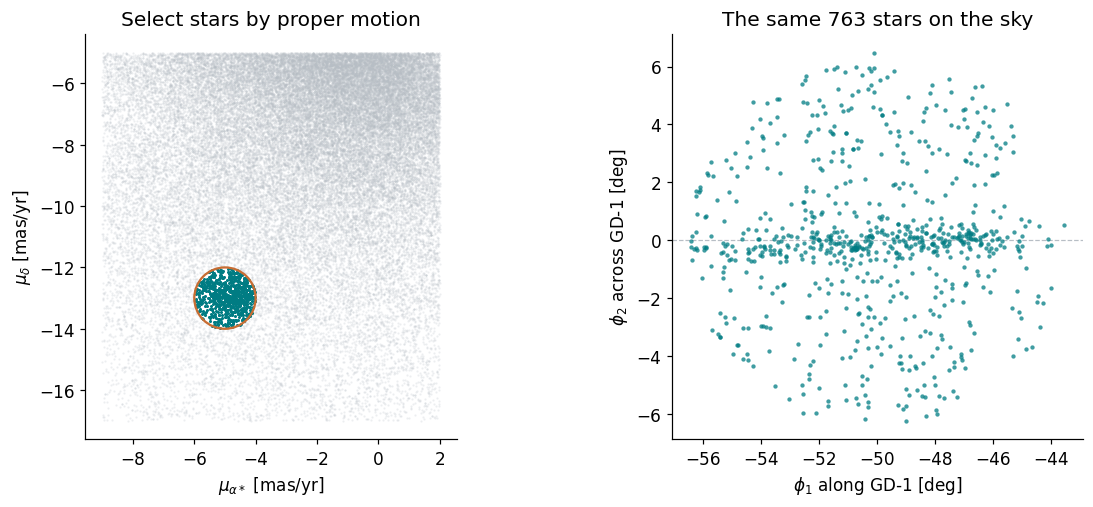

In [51]:
pmra, pmdec = np.asarray(gd1["pmra"]), np.asarray(gd1["pmdec"])
pmra_c, pmdec_c = -5.0, -13.0
radius_pm = 1.0
keep = np.hypot(pmra - pmra_c, pmdec - pmdec_c) < radius_pm

# Rotate the selected sky positions from ICRS into the GD-1 frame.
# Koposov et al. (2010), as implemented in gala's GD1Koposov10.
ra = np.deg2rad(np.asarray(gd1["ra"][keep]))
dec = np.deg2rad(np.asarray(gd1["dec"][keep]))
xyz = np.array([np.cos(dec) * np.cos(ra),
                np.cos(dec) * np.sin(ra),
                np.sin(dec)])

rotation = np.array([
    [-0.4776303088, -0.1738432154,  0.8611897727],
    [ 0.5108445890, -0.8524449229,  0.1112450420],
    [ 0.7147776536,  0.4930681392,  0.4959603976],
])
x, y, z = rotation @ xyz
phi1 = np.rad2deg(np.arctan2(y, x))
phi2 = np.rad2deg(np.arctan2(z, np.hypot(x, y)))

fig, (motion, sky) = plt.subplots(1, 2, figsize=(11, 4.5))

motion.scatter(pmra, pmdec, s=2, color=GREY, alpha=0.25, linewidths=0)
motion.scatter(pmra[keep], pmdec[keep], s=4, color=TEAL, linewidths=0)
motion.add_patch(plt.Circle((pmra_c, pmdec_c), radius_pm,
                            fill=False, color=ORANGE, lw=1.5))
motion.set(xlabel=r"$\mu_{\alpha *}$ [mas/yr]", ylabel=r"$\mu_\delta$ [mas/yr]",
           title="Select stars by proper motion", aspect="equal")

sky.axhline(0, color=GREY, lw=0.8, ls="--", zorder=0)
sky.scatter(phi1, phi2, s=8, color=TEAL, alpha=0.75, linewidths=0)
sky.set(xlabel=r"$\phi_1$ along GD-1 [deg]", ylabel=r"$\phi_2$ across GD-1 [deg]",
        title=f"The same {keep.sum():,} stars on the sky", aspect="equal")

plt.show()

## 4. Just for fun · Spot two stars with Rubin (optional, 10 min)

Two candidates for a different stellar stream, SGP-S, fall in Rubin’s ELAIS-S1 field. Here are their Gaia measurements. Which star would you expect to look brighter in Rubin’s *r* band? What makes that a reasonable guess?

| Candidate | Gaia DR3 source ID | Gaia *G* (mag) | BP − RP (mag) |
|---|---|---:|---:|
| A | 4980391162444934656 | 19.75 | 0.66 |
| B | 4980409235667391360 | 18.95 | 0.70 |

You can have a look at the [Published SGP-S candidate list](https://github.com/abonaca/streams_overview/blob/2663cc06e5ced4b02850de15140bc9f136f3341b/data/members/streams/SGP-S.fits). The stream is proposed here: https://arxiv.org/pdf/2208.05176

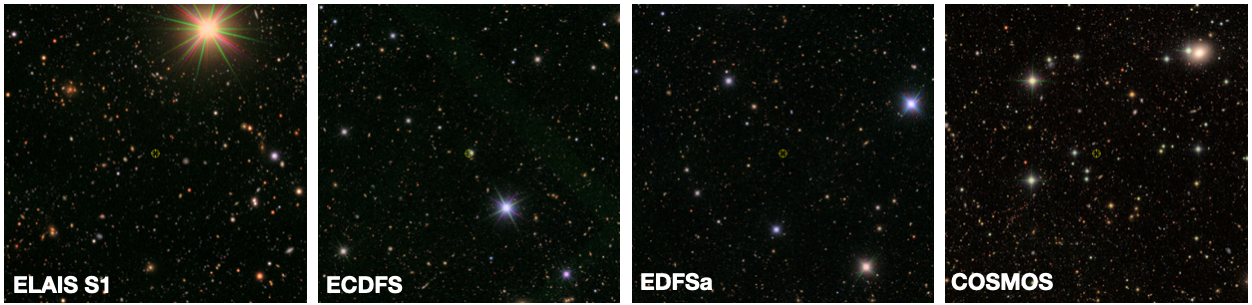

Rubin stacked repeated exposures to make these colour images. The left panel shows a patch of ELAIS-S1. We’ll zoom in on two other positions in that field. These images represent the [Rubin DP2 deep drilling fields](https://dp2.lsst.io/tutorials/notebook/301/notebook-301-3.html#introduction.).

The two target cutouts below use the same brightness scale. Each circle is centred on the Gaia position and has a radius of one arcsecond. Can you pick out a likely counterpart in each image? Look for a neighbouring source that could complicate your choice.

On the Rubin Science Platform, use the LSST kernel, run the setup cells, then set `prepare_rubin` to `True` below and run Q4 once. Save the notebook with its outputs and keep the `gaia_data` folder alongside it. The cells reuse those files on later runs. Reference notebook here: [Rubin image cutout tutorial](https://dp2.lsst.io/tutorials/notebook/104/notebook-104-5.html)

In [52]:
prepare_rubin = True  # Set to True for the first run on the Rubin Science Platform.
# Published Gaia positions (right ascension and declination, in degrees).
positions = {'A': (8.29590721, -43.89209730), 'B': (8.31053446, -43.65938938)}
stamp_files = {label: data_dir / f'sgps_{label}_dp2_r.npz' for label in positions}

In [53]:
# Prepare one 61 × 61 pixel cutout at each Gaia position.
if prepare_rubin and not all(path.exists() for path in stamp_files.values()):
    from astropy.coordinates import SkyCoord
    from lsst.daf.butler import Butler
    from lsst.images import Box

    butler = Butler('dp2', collections='dp2')
    for label, (ra, dec) in positions.items():
        path = stamp_files[label]
        if path.exists():
            continue
        refs = butler.query_datasets('deep_coadd',
                                     where="band.name = 'r' AND patch.region OVERLAPS POINT(ra, dec)",
                                     bind={'ra': ra, 'dec': dec}, explain=False)
        for ref in refs:
            wcs = butler.get('deep_coadd.sky_projection', dataId=ref.dataId)
            xy = wcs.sky_to_pixel(SkyCoord(ra, dec, unit='deg'))
            x, y = round(xy.x), round(xy.y)
            box = Box.factory[y-30:y+31, x-30:x+31]
            bounds = butler.get('deep_coadd.bbox', dataId=ref.dataId)
            if bounds.contains(box):
                pixels = butler.get(ref, parameters={'bbox': box}).image.array
                if np.isfinite(pixels[30, 30]):
                    np.savez_compressed(path, pixels=pixels, x=xy.x - box.x.start, y=xy.y - box.y.start)
                    break
        else:
            print(f'No usable DP2 r-band cutout at the position of {label}.')

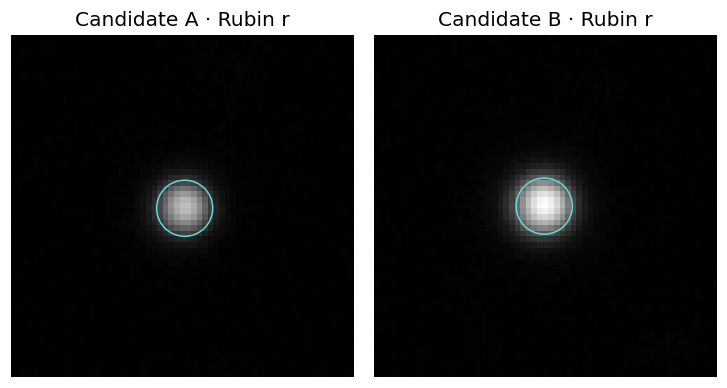

In [54]:
from astropy.visualization import AsinhStretch, ImageNormalize

stamps, centres = {}, {}
for label, path in stamp_files.items():
    if path.exists():
        with np.load(path) as stamp:
            stamps[label] = stamp['pixels']
            centres[label] = (float(stamp['x']), float(stamp['y']))

if stamps:
    sky_level = np.nanpercentile(np.stack(list(stamps.values())), 10)
    peak = max(np.nanmax(image[25:36, 25:36]) for image in stamps.values())
    norm = ImageNormalize(vmin=sky_level, vmax=max(peak, sky_level + 1), stretch=AsinhStretch())
    fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.4))
    for ax, label in zip(axes, positions):
        ax.set_title(f'Candidate {label} · Rubin r')
        ax.set_axis_off()
        if label in stamps:
            ax.imshow(stamps[label], origin='lower', cmap='gray', norm=norm)
            ax.add_patch(plt.Circle(centres[label], 5, fill=False, color='#64D8DB', lw=1))
        else:
            ax.text(.5, .5, 'Cutout unavailable', ha='center', transform=ax.transAxes)
    plt.show()
else:
    print('The candidate cutouts will appear here after the Rubin preparation run.')

**Please check.** How many Rubin catalogue objects fall inside each circle? For a unique match, compare the measured *r* magnitudes with your brightness prediction. What else would you want to measure before calling either star a member of SGP-S?

In [55]:
match_file = data_dir / 'sgps_dp2_matches.ecsv'
if prepare_rubin and not match_file.exists():
    from lsst.rsp import RSPDiscovery
    from astropy.coordinates import SkyCoord

    tap = RSPDiscovery('dp2').get_tap_client()
    rows = []
    for label, (ra, dec) in positions.items():
        query = f"""
            SELECT objectId, coord_ra, coord_dec, r_psfMag
            FROM dp2.Object
            WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec),
                           CIRCLE('ICRS', {ra}, {dec}, {1 / 3600})) = 1
        """
        found = tap.search(query).to_table()
        if len(found) == 1:
            obj = found[0]
            gaia_pos = SkyCoord(ra, dec, unit='deg')
            rubin_pos = SkyCoord(obj['coord_ra'], obj['coord_dec'], unit='deg')
            distance = gaia_pos.separation(rubin_pos).arcsec
            rows.append((label, 1, 'unique', str(obj['objectId']), distance, obj['r_psfMag']))
        else:
            status = 'no match' if len(found) == 0 else 'ambiguous'
            rows.append((label, len(found), status, '—', np.nan, np.nan))
    matches = Table(rows=rows, names=['Star', 'Count', 'Match', 'Rubin ID', 'Offset (arcsec)', 'r (mag)'])
    matches.write(match_file, format='ascii.ecsv')

if match_file.exists():
    matches = Table.read(match_file)
    matches['Offset (arcsec)'].format = '.3f'
    matches['r (mag)'].format = '.2f'
    display(matches)
else:
    print('The catalogue matches will appear here after the Rubin preparation run.')

Star,Count,Match,Rubin ID,Offset (arcsec),r (mag)
str1,int64,str6,str18,float64,float32
A,1,unique,740342685545558742,0.037,19.74
B,1,unique,740344059935087076,0.038,18.97


<details><summary>Check this out after you understand and discuss :-). </summary>

B is brighter in Gaia and the two stars have similar colours, so I would predict B is brighter in Rubin too. A single Rubin object close to the centre of a circle makes a plausible identification across surveys. Two objects inside a circle leave the identification ambiguous. To test stream membership, I would compare each star’s radial velocity with the velocities of SGP-S candidates nearby along the stream.

</details>

## Credits and further reading

The cluster exercises adapt ESA’s Pleiades tutorial. Gaia DR3 supplies the cluster observations and Gaia DR2 supplies the GD-1 field. ESA and the Gaia Data Processing and Analysis Consortium (DPAC) provided the Gaia data. [ESA Gaia notebooks](https://github.com/esa/gaia-jupyter-notebooks) · [Gaia data credits](https://www.cosmos.esa.int/web/gaia-users/credits)

Yang et al. identified SGP-S in Gaia data. The two targets come from the candidate list accompanying Bonaca & Price-Whelan’s review. Q4 uses Rubin DP2 deep coadds and the Object catalogue. [SGP-S discovery paper](https://arxiv.org/abs/2208.05176) · [Stellar streams in the Gaia era](https://doi.org/10.1016/j.newar.2024.101713) · [Rubin DP2 Object catalogue](https://dp2.lsst.io/products/catalogs/object.html)

GPT 6.2 Astra Ultra helped with the notebook.